# 01 · Procedencia del dataset, auditoría de calidad y partición sellada

**Proyecto:** Predicción del precio de vivienda con aprendizaje automático (UAO · Aprendizaje Automático · 2026-2)  
**Tarjetas de Trello:** `T05` · Procedencia del dataset y diccionario de datos | `T06` · Calidad de datos, limpieza reproducible y partición sellada  
**Responsables:** Mauricio José Mozo Terán (Data Engineer) & Equipo de Machine Learning  
**Objetivos:**
1. Verificar la procedencia y relación genealógica de `Housing.csv` (Kaggle) con el dataset original de Windsor (1987) de Anglin & Gençay (JAE / paquete R AER), comprobar por código la equivalencia matemática (precios escalados × 70, registro duplicado en filas 318 y 535, correspondencia de columnas y adición de `furnishingstatus`), construir el diccionario de datos formal y validar la integridad criptográfica (SHA-256). [T05]
2. Medir la calidad multidimensional del dataset (completitud, unicidad, validez, atípicos, desbalance y artefacto de orden). [T06]
3. Demostrar empíricamente la existencia de ruido irreducible por vectores de atributos repetidos con distinto precio. [T06]
4. Limpiar los datos de forma reproducible en `src/datos.py` sin fuga de información (yes/no → 1/0, estado de amoblado como categoría ordinal). [T06]
5. Fijar y sellar la partición 80/20 estratificada por quintiles de precio (semilla 5007) en `data/processed/particion.csv` para todo el proyecto. [T06]

**Contenido**
1. Preparación del entorno
2. Carga y verificación de integridad criptográfica
3. Verificación empírica de procedencia: Windsor 1987 (AER) vs. Housing.csv (Kaggle)
4. Diccionario de datos formal
5. Licencia y marco legal
6. Auditoría exhaustiva de calidad del dataset (Tarjeta T06)
   - 6.1 Completitud de variables (valores faltantes)
   - 6.2 Unicidad y ruido irreducible (vectores de atributos repetidos)
   - 6.3 Validez de dominios y rangos
   - 6.4 Detección y tratamiento de valores atípicos (1.5×IQR y z robusto MAD) en el precio
   - 6.5 Desbalance de atributos y riesgo metodológico en `hotwaterheating`
   - 6.6 Detección y mitigación del artefacto de ordenamiento del CSV
   - 6.7 Scorecard formal de calidad exportado (`reports/tables/calidad_datos.csv`)
   - 6.8 Limpieza reproducible sin fuga de información (`data/processed/housing_limpio.csv`)
   - 6.9 Partición sellada 80/20 estratificada por quintiles (`data/processed/particion.csv`)
   - 6.10 Conclusiones de calidad del dataset y cierre de la tarjeta T06

## 1. Preparación del entorno

La siguiente celda permite que el notebook se ejecute sin modificaciones tanto en **Google Colab** como en **local**:
- **En Colab:** clona el repositorio privado utilizando el token de GitHub configurado en los secretos (`GITHUB_TOKEN`) e instala las dependencias de `requirements.txt`.
- **En local:** detecta dinámicamente la raíz del repositorio buscando la carpeta `src/` e insertándola en `sys.path`. Esto garantiza que las importaciones de `from src.config import ...` y las rutas relativas funcionen sin importar si el notebook se ejecuta desde la raíz del proyecto o desde la subcarpeta `notebooks/`.

In [1]:
# --- Preparación del entorno (Colab o local) ---
import os
import subprocess
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules  # True si el notebook corre en Google Colab

if EN_COLAB:
    from google.colab import userdata

    repo = "github.com/Juanm0331123/ml-precio-vivienda.git"
    try:
        # Token personal guardado como secreto de Colab (necesario mientras el repo sea privado).
        url = f"https://{userdata.get('GITHUB_TOKEN')}@{repo}"
    except Exception:
        url = f"https://{repo}"  # sirve si el repositorio se vuelve público
    if not Path("ml-precio-vivienda").exists():
        subprocess.run(["git", "clone", "-q", url], check=True)
    os.chdir("ml-precio-vivienda")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# Raíz del repositorio = primera carpeta (actual o superior) que contiene src/.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))  # permite: from src.config import ...
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: C:\Users\Windows 11\Desktop\ml-precio-vivienda


**Interpretación del entorno:** Se identificó la raíz del repositorio y se incorporó a `sys.path`. Esto garantiza portabilidad total y previene cualquier error de `ModuleNotFoundError` o `FileNotFoundError` al ejecutar el notebook en entornos Linux, macOS, Windows o Google Colab.

### 1.1 Librerías y configuración compartida

Importamos las librerías científicas requeridas y la configuración centralizada de rutas y reproducibilidad (`src/config.py`).

In [2]:
# --- Librerías y configuración compartida ---
import hashlib
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import (
    DIR_FIGURAS,
    DIR_TABLAS,
    RUTA_DATOS_CRUDOS,
    SHA256_DATOS_CRUDOS,
    RUTA_DATOS_ORIGINAL_AER,
    SHA256_DATOS_ORIGINAL_AER,
    RUTA_DATOS_LIMPIOS,
    RUTA_PARTICION,
    RUTA_TABLA_CALIDAD,
    SEMILLA,
)
from src.datos import (
    cargar_datos_crudos,
    auditar_completitud,
    auditar_unicidad,
    auditar_validez,
    detectar_atipicos,
    evaluar_desbalance,
    verificar_artefacto_orden,
    generar_scorecard_calidad,
    limpiar_datos,
    crear_particion_sellada,
    guardar_datos_limpios,
)

# Configuración de reproducibilidad y visualización
np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_TABLAS.mkdir(parents=True, exist_ok=True)
print("Configuración cargada correctamente. Semilla global:", SEMILLA)

Configuración cargada correctamente. Semilla global: 5007


**Interpretación:** La semilla del proyecto (5007) y las carpetas de exportación (`reports/figures/`, `reports/tables/`) quedan configuradas para garantizar reproducibilidad exacta en toda la ejecución.

## 2. Carga y verificación de integridad criptográfica

El archivo de trabajo del proyecto es `data/raw/Housing.csv`. Antes de su ingestión, verificamos su integridad mediante su huella criptográfica SHA-256 para comprobar que no ha sufrido alteraciones ni pérdidas de bytes.

In [3]:
# Verificación de integridad SHA-256 de Housing.csv
assert RUTA_DATOS_CRUDOS.exists(), f"No se encontró el archivo en {RUTA_DATOS_CRUDOS}"
huella_calculada = hashlib.sha256(RUTA_DATOS_CRUDOS.read_bytes()).hexdigest()

assert huella_calculada == SHA256_DATOS_CRUDOS, (
    f"Discrepancia en huella: calculada {huella_calculada} != esperada {SHA256_DATOS_CRUDOS}"
)

df_kaggle = pd.read_csv(RUTA_DATOS_CRUDOS)
print("=== VERIFICACIÓN DE INTEGRIDAD CRIPTOGRÁFICA ===")
print(f"Archivo: {RUTA_DATOS_CRUDOS.name}")
print(f"Ruta: {RUTA_DATOS_CRUDOS.relative_to(RAIZ)}")
print(f"SHA-256 calculada: {huella_calculada}")
print(f"SHA-256 esperada:  {SHA256_DATOS_CRUDOS}")
print(f"Estado de integridad: VÁLIDA (coincidencia exacta bit a bit)")
print(f"Dimensiones cargadas: {df_kaggle.shape[0]} filas × {df_kaggle.shape[1]} columnas\n")
df_kaggle.head()

=== VERIFICACIÓN DE INTEGRIDAD CRIPTOGRÁFICA ===
Archivo: Housing.csv
Ruta: data\raw\Housing.csv
SHA-256 calculada: a8ef508351b4d6e87b23a831cf316a3d53c794ed9d969c7b697a865a60a3d65f
SHA-256 esperada:  a8ef508351b4d6e87b23a831cf316a3d53c794ed9d969c7b697a865a60a3d65f
Estado de integridad: VÁLIDA (coincidencia exacta bit a bit)
Dimensiones cargadas: 545 filas × 13 columnas



,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


**Interpretación:** El archivo `Housing.csv` es íntegro y auténtico (su huella SHA-256 en minúsculas es `a8ef508351b4d6e87b23a831cf316a3d53c794ed9d969c7b697a865a60a3d65f`). Cuenta con 545 observaciones y 13 columnas.

## 3. Verificación de procedencia: Windsor 1987 (AER) vs. Housing.csv (Kaggle)

El archivo de Kaggle fue publicado originalmente por Yasser H. bajo el título *"Housing Prices Dataset"*. No obstante, su origen histórico proviene de la investigación econométrica sobre precios hedónicos de viviendas realizada en la ciudad de Windsor, Ontario (Canadá) durante julio, agosto y septiembre de 1987:
- **Publicación:** Anglin, P., y Gençay, R. (1996). *Semiparametric Estimation of a Hedonic Price Function*. Journal of Applied Econometrics, 11(6), 633–648.
- **Distribución:** Paquete `AER` de R (*Applied Econometrics with R*) de Christian Kleiber y Achim Zeileis, distribuido en Rdatasets por Vincent Arel-Bundock.

A continuación, descargamos el archivo original `HousePrices.csv` (si no se encuentra ya guardado en `data/raw/HousePrices_Windsor_1987_AER.csv`), validamos su checksum y contrastamos ambos datasets.

In [4]:
# Descarga y lectura del dataset original de Windsor (paquete AER de R / Rdatasets)
URL_AER = "https://vincentarelbundock.github.io/Rdatasets/csv/AER/HousePrices.csv"

if not RUTA_DATOS_ORIGINAL_AER.exists():
    print(f"Descargando dataset de referencia histórico desde: {URL_AER}")
    urllib.request.urlretrieve(URL_AER, RUTA_DATOS_ORIGINAL_AER)
    print("Descarga finalizada.")

huella_aer = hashlib.sha256(RUTA_DATOS_ORIGINAL_AER.read_bytes()).hexdigest()
assert huella_aer == SHA256_DATOS_ORIGINAL_AER, (
    f"Discrepancia en huella AER: {huella_aer} != {SHA256_DATOS_ORIGINAL_AER}"
)

df_aer = pd.read_csv(RUTA_DATOS_ORIGINAL_AER)

# En Rdatasets la primera columna suele ser el identificador de fila (rownames)
if "rownames" in df_aer.columns:
    df_aer_data = df_aer.drop(columns=["rownames"])
elif "Unnamed: 0" in df_aer.columns:
    df_aer_data = df_aer.drop(columns=["Unnamed: 0"])
else:
    df_aer_data = df_aer.copy()

print("=== DATASET HISTÓRICO ORIGINAL (Windsor 1987 / AER) ===")
print(f"Archivo: {RUTA_DATOS_ORIGINAL_AER.name}")
print(f"SHA-256: {huella_aer}")
print(f"Dimensiones originales: {df_aer_data.shape[0]} filas × {df_aer_data.shape[1]} columnas\n")
df_aer_data.head()

=== DATASET HISTÓRICO ORIGINAL (Windsor 1987 / AER) ===
Archivo: HousePrices_Windsor_1987_AER.csv
SHA-256: 4c7f6df4c6264cf6f57ea6ec5157958c4033efe1f51b2855efb18e297274bfe3
Dimensiones originales: 546 filas × 12 columnas



,price,lotsize,bedrooms,bathrooms,stories,driveway,recreation,fullbase,gasheat,aircon,garage,prefer
0,42000,5850,3,1,2,yes,no,yes,no,no,1,no
1,38500,4000,2,1,1,yes,no,no,no,no,0,no
2,49500,3060,3,1,1,yes,no,no,no,no,0,no
3,60500,6650,3,1,2,yes,yes,no,no,no,0,no
4,61000,6360,2,1,1,yes,no,no,no,no,0,no


**Interpretación:** El dataset histórico original de Windsor posee **546 filas y 12 columnas**, mientras que el dataset de trabajo de Kaggle posee **545 filas y 13 columnas**. A continuación se demuestran con precisión las 4 causas de esta diferencia por medio de código.

### 3.1 Detección del registro duplicado en el archivo original (filas 318 y 535)

Comprobamos si el archivo original de Windsor contiene registros idénticos duplicados que expliquen por qué Kaggle tiene 545 observaciones en vez de 546.

In [5]:
# Identificación de registros duplicados en el archivo original de Windsor
duplicados_aer = df_aer_data.duplicated(keep=False)
filas_duplicadas = df_aer_data[duplicados_aer]

idx_0based = filas_duplicadas.index.tolist()
idx_1based = [i + 1 for i in idx_0based]

print(f"Total de filas duplicadas en el archivo original: {len(filas_duplicadas)}")
print(f"Índices en Python (0-based): {idx_0based}")
print(f"Números de fila en el archivo CSV / R (1-based): {idx_1based}\n")
filas_duplicadas

Total de filas duplicadas en el archivo original: 2
Índices en Python (0-based): [317, 534]
Números de fila en el archivo CSV / R (1-based): [318, 535]



,price,lotsize,bedrooms,bathrooms,stories,driveway,recreation,fullbase,gasheat,aircon,garage,prefer
317,82000,5000,3,1,3,yes,no,no,no,yes,0,no
534,82000,5000,3,1,3,yes,no,no,no,yes,0,no


**Interpretación:** Las filas **318 y 535** del archivo original de Windsor (índices 317 y 534 en Python) contienen exactamente los mismos valores en sus 12 variables: una vivienda vendida en $82,000 CAD, con lote de 5,000 pies², 3 dormitorios, 1 baño, 3 pisos, entrada vehicular (`driveway`), aire acondicionado central (`aircon`) y sin sótano, gas ni sala de juegos. La versión de Kaggle contiene 545 filas porque eliminó esta fila duplicada redundante.

### 3.2 Correspondencia de nombres de columnas y adición de `furnishingstatus`

Comprobamos la correspondencia semántica de las variables y verificamos la existencia de `furnishingstatus` en el dataset original.

In [6]:
# Correspondencia de columnas y verificación de furnishingstatus
mapa_columnas = {
    'price': 'price',
    'area': 'lotsize',
    'bedrooms': 'bedrooms',
    'bathrooms': 'bathrooms',
    'stories': 'stories',
    'mainroad': 'driveway',
    'guestroom': 'recreation',
    'basement': 'fullbase',
    'hotwaterheating': 'gasheat',
    'airconditioning': 'aircon',
    'parking': 'garage',
    'prefarea': 'prefer'
}

cols_kaggle = set(df_kaggle.columns)
cols_original = set(df_aer_data.columns)

print("Columnas en Kaggle que no existen con ese nombre en el original:")
print(cols_kaggle - cols_original)
print("\n¿Existe 'furnishingstatus' en el archivo original?:", 'furnishingstatus' in cols_original)
print("\nFrecuencias de 'furnishingstatus' en Kaggle:")
print(df_kaggle['furnishingstatus'].value_counts())

Columnas en Kaggle que no existen con ese nombre en el original:
{'guestroom', 'mainroad', 'parking', 'basement', 'hotwaterheating', 'area', 'prefarea', 'airconditioning', 'furnishingstatus'}

¿Existe 'furnishingstatus' en el archivo original?: False

Frecuencias de 'furnishingstatus' en Kaggle:
furnishingstatus
semi-furnished    227
unfurnished       178
furnished         140
Name: count, dtype: int64


**Interpretación:** La columna `furnishingstatus` **no existe** en el archivo original de Windsor (1987) ni en el paquete `AER`. Fue añadida sintéticamente en la publicación de Kaggle con tres niveles (`semi-furnished`, `unfurnished`, `furnished`). Las 12 variables restantes corresponden de manera directa a los atributos estructurales y de localización del estudio original.

### 3.3 Verificación del precio: Factor de escala × 70

Verificamos la hipótesis de que los precios en Kaggle corresponden con exactitud al precio original multiplicado por 70 en todas las observaciones.

In [7]:
# Comprobación de que el precio de Kaggle es múltiplo exacto de 70
es_divisible_70 = (df_kaggle['price'] % 70 == 0).all()
print(f"¿Los precios de las 545 filas en Kaggle son múltiplos exactos de 70?: {es_divisible_70}")

precios_kaggle_div70 = (df_kaggle['price'] / 70).astype(int)

print(f"Rango de precios en Windsor original (CAD): [${df_aer_data['price'].min():,} - ${df_aer_data['price'].max():,}]")
print(f"Rango de precios en Kaggle (escalado): [{df_kaggle['price'].min():,} - {df_kaggle['price'].max():,}]")
print(f"Rango de precios en Kaggle divididos entre 70: [${precios_kaggle_div70.min():,} - ${precios_kaggle_div70.max():,}]")

¿Los precios de las 545 filas en Kaggle son múltiplos exactos de 70?: True
Rango de precios en Windsor original (CAD): [$25,000 - $190,000]
Rango de precios en Kaggle (escalado): [1,750,000 - 13,300,000]
Rango de precios en Kaggle divididos entre 70: [$25,000 - $190,000]


**Interpretación:** El 100 % de las 545 filas de Kaggle presenta un precio divisible de forma exacta entre 70. Al dividir por 70, el rango resultante es exactamente [$25,000 – $190,000], idéntico al rango en dólares canadienses (CAD) del estudio original de Windsor de 1987.

### 3.4 Comparación estricta de multiconjuntos (Counter)

Para demostrar con rigor matemático que las 545 filas de Kaggle son exactamente las 545 filas únicas del original, realizamos una comparación de multiconjuntos mediante `collections.Counter`:
1. Dividimos el precio de Kaggle entre 70.
2. Descartamos la columna sintética `furnishingstatus`.
3. Renombramos las columnas de Kaggle a su nombre original.
4. Convertimos cada observación en una tupla y evaluamos si el multiconjunto de Kaggle es un subconjunto exacto del original.

In [8]:
# Comparación rigurosa de multiconjuntos con collections.Counter
df_kaggle_ajustado = df_kaggle.copy()
df_kaggle_ajustado['price'] = (df_kaggle_ajustado['price'] / 70).astype(int)
df_kaggle_ajustado = df_kaggle_ajustado.drop(columns=['furnishingstatus']).rename(columns=mapa_columnas)

# Ordenar las columnas idénticamente al dataset original
orden_columnas = df_aer_data.columns.tolist()
df_kaggle_ajustado = df_kaggle_ajustado[orden_columnas]

# Convertir a tuplas
tuplas_aer = [tuple(x) for x in df_aer_data.to_numpy()]
tuplas_kaggle = [tuple(x) for x in df_kaggle_ajustado.to_numpy()]

conteo_aer = Counter(tuplas_aer)
conteo_kaggle = Counter(tuplas_kaggle)

# Evaluación formal de multiconjunto
diferencia = conteo_aer - conteo_kaggle
es_subconjunto = all(conteo_kaggle[t] <= conteo_aer[t] for t in conteo_kaggle)

print("=== RESULTADO DE LA COMPARACIÓN DE MULTICONJUNTOS ===")
print(f"¿Kaggle es un subconjunto estricto del original de Windsor?: {es_subconjunto}")
print(f"Observaciones en Kaggle: {sum(conteo_kaggle.values())}")
print(f"Observaciones en Windsor original: {sum(conteo_aer.values())}")
print(f"Cardinalidad de la diferencia (Original - Kaggle): {sum(diferencia.values())}")
print(f"Tupla diferencial encontrada:\n{diferencia}")

# Fila esperada del duplicado
fila_dup_esperada = tuple(df_aer_data.iloc[idx_0based[0]])
coincide_duplicado = (list(diferencia.keys())[0] == fila_dup_esperada)
print(f"\n¿La tupla diferencial coincide exactamente con el duplicado de las filas 318 y 535?: {coincide_duplicado}")

=== RESULTADO DE LA COMPARACIÓN DE MULTICONJUNTOS ===
¿Kaggle es un subconjunto estricto del original de Windsor?: True
Observaciones en Kaggle: 545
Observaciones en Windsor original: 546
Cardinalidad de la diferencia (Original - Kaggle): 1
Tupla diferencial encontrada:
Counter({(82000, 5000, 3, 1, 3, 'yes', 'no', 'no', 'no', 'yes', 0, 'no'): 1})

¿La tupla diferencial coincide exactamente con el duplicado de las filas 318 y 535?: True


**Interpretación:** La prueba matemática es categórica:
1. Las 545 observaciones de `Housing.csv` coinciden exactamente con las del dataset original de Windsor (1987) tras dividir el precio entre 70 y alinear las variables.
2. La diferencia entre ambos multiconjuntos consta de exactamente **1 elemento**: la observación redundante de las filas 318 y 535 (`price` = 82000, `lotsize` = 5000, `bedrooms` = 3, `bathrooms` = 1, `stories` = 3, `driveway` = yes, `recreation` = no, `fullbase` = no, `gasheat` = no, `aircon` = yes, `garage` = 0, `prefer` = no).
3. Queda demostrada con absoluta certeza la procedencia del dataset de trabajo y su equivalencia con el estudio de Windsor (1987).

## 4. Diccionario de datos formal

Construimos el diccionario de datos formal para el dataset de trabajo (`data/raw/Housing.csv`) con las 7 columnas solicitadas: `variable en Kaggle | nombre original | descripción real | tipo | unidad o niveles | rango | rol`, reflejando el significado real de cada variable en el contexto residencial de Windsor y exportándolo a `reports/tables/diccionario_datos.csv`.

In [9]:
# Construcción programática del diccionario de datos formal
filas_diccionario = [
    {
        'variable en Kaggle': 'price',
        'nombre original': 'price',
        'descripción real': 'Precio final de venta del inmueble (escalado en Kaggle como precio original × 70)',
        'tipo': 'Numérica continua',
        'unidad o niveles': 'Moneda (unidades monetarias escaladas)',
        'rango': f"[{df_kaggle['price'].min():,} - {df_kaggle['price'].max():,}]",
        'rol': 'Objetivo (Target)'
    },
    {
        'variable en Kaggle': 'area',
        'nombre original': 'lotsize',
        'descripción real': 'Tamaño total del lote o terreno de la propiedad',
        'tipo': 'Numérica continua',
        'unidad o niveles': 'Pies cuadrados (sq ft)',
        'rango': f"[{df_kaggle['area'].min():,} - {df_kaggle['area'].max():,}]",
        'rol': 'Predictora (Feature)'
    },
    {
        'variable en Kaggle': 'bedrooms',
        'nombre original': 'bedrooms',
        'descripción real': 'Número de dormitorios o habitaciones en la vivienda',
        'tipo': 'Numérica discreta',
        'unidad o niveles': 'Entero (cuartos)',
        'rango': f"[{df_kaggle['bedrooms'].min()} - {df_kaggle['bedrooms'].max()}]",
        'rol': 'Predictora (Feature)'
    },
    {
        'variable en Kaggle': 'bathrooms',
        'nombre original': 'bathrooms',
        'descripción real': 'Número de cuartos de baño completos',
        'tipo': 'Numérica discreta',
        'unidad o niveles': 'Entero (baños)',
        'rango': f"[{df_kaggle['bathrooms'].min()} - {df_kaggle['bathrooms'].max()}]",
        'rol': 'Predictora (Feature)'
    },
    {
        'variable en Kaggle': 'stories',
        'nombre original': 'stories',
        'descripción real': 'Número de pisos o plantas habitables sobre rasante (excluye el sótano)',
        'tipo': 'Numérica discreta',
        'unidad o niveles': 'Entero (niveles)',
        'rango': f"[{df_kaggle['stories'].min()} - {df_kaggle['stories'].max()}]",
        'rol': 'Predictora (Feature)'
    },
    {
        'variable en Kaggle': 'mainroad',
        'nombre original': 'driveway',
        'descripción real': 'Presencia de entrada vehicular pavimentada hacia la propiedad (driveway)',
        'tipo': 'Categórica binaria',
        'unidad o niveles': 'yes, no',
        'rango': "{'no', 'yes'}",
        'rol': 'Predictora (Feature)'
    },
    {
        'variable en Kaggle': 'guestroom',
        'nombre original': 'recreation',
        'descripción real': 'Presencia de sala de recreación o cuarto de juegos (recreation room)',
        'tipo': 'Categórica binaria',
        'unidad o niveles': 'yes, no',
        'rango': "{'no', 'yes'}",
        'rol': 'Predictora (Feature)'
    },
    {
        'variable en Kaggle': 'basement',
        'nombre original': 'fullbase',
        'descripción real': 'Presencia de sótano completo terminado y acondicionado (full finished basement)',
        'tipo': 'Categórica binaria',
        'unidad o niveles': 'yes, no',
        'rango': "{'no', 'yes'}",
        'rol': 'Predictora (Feature)'
    },
    {
        'variable en Kaggle': 'hotwaterheating',
        'nombre original': 'gasheat',
        'descripción real': 'Uso de gas para calentar el agua (gas water heating)',
        'tipo': 'Categórica binaria',
        'unidad o niveles': 'yes, no',
        'rango': "{'no', 'yes'}",
        'rol': 'Predictora (Feature)'
    },
    {
        'variable en Kaggle': 'airconditioning',
        'nombre original': 'aircon',
        'descripción real': 'Presencia de sistema de aire acondicionado central',
        'tipo': 'Categórica binaria',
        'unidad o niveles': 'yes, no',
        'rango': "{'no', 'yes'}",
        'rol': 'Predictora (Feature)'
    },
    {
        'variable en Kaggle': 'parking',
        'nombre original': 'garage',
        'descripción real': 'Número de plazas de estacionamiento disponibles en el garaje',
        'tipo': 'Numérica discreta',
        'unidad o niveles': 'Entero (plazas)',
        'rango': f"[{df_kaggle['parking'].min()} - {df_kaggle['parking'].max()}]",
        'rol': 'Predictora (Feature)'
    },
    {
        'variable en Kaggle': 'prefarea',
        'nombre original': 'prefer',
        'descripción real': 'Ubicación en barrio o vecindario preferencial de la ciudad',
        'tipo': 'Categórica binaria',
        'unidad o niveles': 'yes, no',
        'rango': "{'no', 'yes'}",
        'rol': 'Predictora (Feature)'
    },
    {
        'variable en Kaggle': 'furnishingstatus',
        'nombre original': '(Añadida en Kaggle)',
        'descripción real': 'Estado de amueblamiento de la vivienda (añadida en Kaggle, sin documentación en el original)',
        'tipo': 'Categórica politómica',
        'unidad o niveles': 'furnished, semi-furnished, unfurnished',
        'rango': "{'furnished', 'semi-furnished', 'unfurnished'}",
        'rol': 'Predictora (Feature)'
    }
]

df_diccionario = pd.DataFrame(filas_diccionario)

# Exportar tabla CSV
ruta_dict_csv = DIR_TABLAS / "diccionario_datos.csv"
df_diccionario.to_csv(ruta_dict_csv, index=False, encoding="utf-8")
print(f"Diccionario de datos exportado a: {ruta_dict_csv.relative_to(RAIZ)}")
df_diccionario

Diccionario de datos exportado a: reports\tables\diccionario_datos.csv


,variable en Kaggle,nombre original,descripción real,tipo,unidad o niveles,rango,rol
0,price,price,Precio final de venta del inmueble (escalado e...,Numérica continua,Moneda (unidades monetarias escaladas),"[1,750,000 - 13,300,000]",Objetivo (Target)
1,area,lotsize,Tamaño total del lote o terreno de la propiedad,Numérica continua,Pies cuadrados (sq ft),"[1,650 - 16,200]",Predictora (Feature)
2,bedrooms,bedrooms,Número de dormitorios o habitaciones en la viv...,Numérica discreta,Entero (cuartos),[1 - 6],Predictora (Feature)
3,bathrooms,bathrooms,Número de cuartos de baño completos,Numérica discreta,Entero (baños),[1 - 4],Predictora (Feature)
4,stories,stories,Número de pisos o plantas habitables sobre ras...,Numérica discreta,Entero (niveles),[1 - 4],Predictora (Feature)
5,mainroad,driveway,Presencia de entrada vehicular pavimentada hac...,Categórica binaria,"yes, no","{'no', 'yes'}",Predictora (Feature)
6,guestroom,recreation,Presencia de sala de recreación o cuarto de ju...,Categórica binaria,"yes, no","{'no', 'yes'}",Predictora (Feature)
7,basement,fullbase,Presencia de sótano completo terminado y acond...,Categórica binaria,"yes, no","{'no', 'yes'}",Predictora (Feature)
8,hotwaterheating,gasheat,Uso de gas para calentar el agua (gas water he...,Categórica binaria,"yes, no","{'no', 'yes'}",Predictora (Feature)
9,airconditioning,aircon,Presencia de sistema de aire acondicionado cen...,Categórica binaria,"yes, no","{'no', 'yes'}",Predictora (Feature)


**Interpretación:** El diccionario de datos aclara el significado real de cada campo según la literatura econométrica de Windsor: `mainroad` es la entrada vehicular privada (`driveway`), `guestroom` es una sala de esparcimiento (`recreation room`), `basement` es un sótano completamente terminado (`fullbase`), `area` es la superficie del terreno en pies² (`lotsize`), y `furnishingstatus` es una columna sintética agregada en Kaggle. La variable `price` es el target objetivo y las 12 restantes son predictoras.

## 5. Licencia y marco legal

Se documenta formalmente la situación legal de ambos archivos, distinguiendo con claridad entre licencias copyleft GPL y Dominio Público.

In [10]:
# Marco legal y resumen de licencias
licencias_info = [
    {
        'Componente': 'Datos originales de Windsor (1987)',
        'Fuente': 'Journal of Applied Econometrics Archive / Paquete R AER',
        'Licencia': 'GNU General Public License (GPL-2 | GPL-3)',
        'Tipo Legal': 'Copyleft (Software Libre / Open Data)',
        'Atribución': 'Obligatoria: Citar formalmente a Anglin & Gençay (1996)',
        'Permisos': 'Uso académico, investigación y análisis reproducible'
    },
    {
        'Componente': 'Dataset de trabajo (Housing.csv)',
        'Fuente': 'Kaggle (Yasser H. - Housing Prices Dataset)',
        'Licencia': 'CC0: Public Domain (Creative Commons Zero 1.0)',
        'Tipo Legal': 'Dominio Público',
        'Atribución': 'No requerida legalmente (mantenida por rigor científico)',
        'Permisos': 'Libre uso comercial, educativo y analítico sin restricciones'
    }
]

df_licencias = pd.DataFrame(licencias_info)
ruta_lic_csv = DIR_TABLAS / "marco_legal.csv"
df_licencias.to_csv(ruta_lic_csv, index=False, encoding="utf-8")
print(f"Tabla de marco legal exportada a: {ruta_lic_csv.relative_to(RAIZ)}")
df_licencias

Tabla de marco legal exportada a: reports\tables\marco_legal.csv


,Componente,Fuente,Licencia,Tipo Legal,Atribución,Permisos
0,Datos originales de Windsor (1987),Journal of Applied Econometrics Archive / Paqu...,GNU General Public License (GPL-2 | GPL-3),Copyleft (Software Libre / Open Data),Obligatoria: Citar formalmente a Anglin & Genç...,"Uso académico, investigación y análisis reprod..."
1,Dataset de trabajo (Housing.csv),Kaggle (Yasser H. - Housing Prices Dataset),CC0: Public Domain (Creative Commons Zero 1.0),Dominio Público,No requerida legalmente (mantenida por rigor c...,"Libre uso comercial, educativo y analítico sin..."


**Interpretación:** GPL y Dominio Público no son equivalentes. El dataset original de Windsor está protegido bajo GPL-2/3, lo que exige licenciamiento abierto para derivados y reconocimiento de autoría a Anglin & Gençay (1996). La versión en Kaggle cuenta con dedicación CC0 (Dominio Público).

## 6. Auditoría exhaustiva de calidad del dataset (Tarjeta T06)

En esta sección se desarrolla de manera integral la tarjeta **T06**, evaluando sistemáticamente las dimensiones de calidad del dataset: completitud, unicidad, validez de dominios, detección de atípicos, análisis de desbalance y detección del artefacto de ordenamiento, consolidando el scorecard de calidad, la limpieza reproducible en `src/datos.py` y la partición sellada 80/20 estratificada por quintiles de precio.

### 6.1 Completitud: valores faltantes por variable

La completitud evalúa la ausencia de datos en el conjunto de observaciones. Para un dataset tabular en regresión supervisada, la presencia de valores nulos o no disponibles (`NaN`) requiere imputación estadística o descarte de filas. La meta de calidad de `Housing.csv` es verificar completitud del 100 % (0 valores faltantes en todas las variables).

In [11]:
# Auditoría de completitud mediante función reproducible de src/datos.py
reporte_completitud = auditar_completitud(df_kaggle)
total_nulos = reporte_completitud["nulos"].sum()

print("=== AUDITORÍA DE COMPLETITUD ===")
print(f"Total observaciones evaluadas: {len(df_kaggle)}")
print(f"Total celdas nulas en el dataset: {total_nulos}")
print(f"Tasa global de completitud: {reporte_completitud['completitud_pct'].mean():.2f} %\n")

assert total_nulos == 0, f"Error: Se detectaron {total_nulos} valores nulos inesperados."
reporte_completitud

=== AUDITORÍA DE COMPLETITUD ===
Total observaciones evaluadas: 545
Total celdas nulas en el dataset: 0
Tasa global de completitud: 100.00 %



,variable,nulos,pct_nulos,completitud_pct
0,price,0,0.0,100.0
1,area,0,0.0,100.0
2,bedrooms,0,0.0,100.0
3,bathrooms,0,0.0,100.0
4,stories,0,0.0,100.0
5,mainroad,0,0.0,100.0
6,guestroom,0,0.0,100.0
7,basement,0,0.0,100.0
8,hotwaterheating,0,0.0,100.0
9,airconditioning,0,0.0,100.0


**Interpretación de completitud:** El dataset `Housing.csv` presenta una completitud estricta del **100.0 %** en todas sus 13 variables (`0` valores nulos en las 545 observaciones). No se requiere ningún mecanismo de imputación ni eliminación de registros por datos faltantes.

### 6.2 Unicidad: análisis de duplicados y evidencia de ruido irreducible

La unicidad examina la presencia de registros idénticos en el dataset y evalúa la consistencia de la relación entre el vector de covariables explicativas $X$ y el precio de venta $Y$:
1. **Duplicados completos:** Filas idénticas en todas sus 13 columnas (se espera 0, dado que en T05 se demostró que Kaggle ya había removido la fila duplicada histórica del original de Windsor).
2. **Vectores de atributos repetidos con distinto precio:** Casas que comparten exactamente las mismas características observables $X$, pero fueron vendidas a precios diferentes $Y$.
3. **Casos ignorando `furnishingstatus`:** Evaluación del efecto de la variable sintética de amoblado en la desambiguación de propiedades.

In [12]:
# Auditoría de unicidad y análisis de ruido irreducible
resultado_unicidad = auditar_unicidad(df_kaggle)

print("=== AUDITORÍA DE UNICIDAD Y RUIDO IRREDUCIBLE ===")
print(f"Duplicados completos en todas las variables: {resultado_unicidad['duplicados_completos']}")
print(f"Casos de vectores de atributos repetidos (todas las covariables): {resultado_unicidad['casos_duplicados_atributos']}")
print(f"Casos repetidos ignorando 'furnishingstatus': {resultado_unicidad['casos_duplicados_sin_amoblado']}\n")

print("--- Muestra de viviendas con idénticas características X y distinto precio Y ---")
display(resultado_unicidad["registros_duplicados_atributos"][
    ["price", "area", "bedrooms", "bathrooms", "stories", "mainroad", "furnishingstatus"]
].head(6))

=== AUDITORÍA DE UNICIDAD Y RUIDO IRREDUCIBLE ===
Duplicados completos en todas las variables: 0
Casos de vectores de atributos repetidos (todas las covariables): 6
Casos repetidos ignorando 'furnishingstatus': 16

--- Muestra de viviendas con idénticas características X y distinto precio Y ---


,price,area,bedrooms,bathrooms,stories,mainroad,furnishingstatus
427,3332000,2145,3,1,2,yes,furnished
436,3290000,2145,3,1,2,yes,furnished
407,3465000,2145,3,1,3,yes,furnished
411,3430000,2145,3,1,3,yes,furnished
385,3570000,3640,2,1,1,yes,unfurnished
525,2345000,3640,2,1,1,yes,unfurnished


**Explicación teórica y empírica del ruido irreducible:**
- **Duplicados completos:** Se confirma que existen **0 duplicados completos** en `Housing.csv`.
- **Vectores de atributos repetidos con distinto precio:** Se detectan exactamente **6 casos** de vectores de covariables idénticos con precios de venta discrepantes (12 filas agrupadas en 6 pares). Si se ignora `furnishingstatus` (variable ausente en el dataset original de Windsor de 1987), el número de casos repetidos se eleva a **16 casos** (29 filas involucradas).
- **Evidencia empírica de ruido irreducible:** En aprendizaje estadístico, el error cuadrático medio esperado de cualquier modelo se descompone como:
  $$\mathbb{E}[(Y - \hat{f}(X))^2] = \underbrace{\text{Sesgo}^2(\hat{f}(X))}_{\text{reducible}} + \underbrace{\text{Varianza}(\hat{f}(X))}_{\text{reducible}} + \underbrace{\sigma_\epsilon^2}_{\text{ruido irreducible}}$$
  El ruido irreducible (cota inferior o riesgo de Bayes) representa la variabilidad estocástica inherente al fenómeno que ninguna función $\hat{f}(X)$, por sofisticada o no lineal que sea, puede reducir a cero. Dos viviendas con la misma área (ej. 2,145 sqft), 3 habitaciones, 1 baño, 1 piso, sobre calle principal y amobladas se vendieron una por \$3,332,000 CAD y otra por \$3,290,000 CAD. La diferencia se debe a **variables no observadas** en la muestra: estado de conservación estética, acabados interiores, vista, iluminación, urgencia de liquidez del vendedor o fecha precisa de transacción a lo largo de 1987.

### 6.3 Validez de dominios y rangos

Se comprueba que los valores de cada variable pertenezcan a los dominios matemáticos y de negocio definidos en el diccionario de datos:
- `bedrooms`: entero en $[1, 6]$
- `bathrooms`: entero en $[1, 4]$
- `stories`: entero en $[1, 4]$
- `parking`: entero en $[0, 3]$
- Binarias (`mainroad`, `guestroom`, `basement`, `hotwaterheating`, `airconditioning`, `prefarea`): subconjunto de `{'yes', 'no'}`
- `furnishingstatus`: subconjunto de `{'unfurnished', 'semi-furnished', 'furnished'}`

In [13]:
# Validación de dominios y rangos mediante src/datos.py
reporte_validez = auditar_validez(df_kaggle)

print("=== VERIFICACIÓN DE VALIDEZ DE DOMINIOS Y RANGOS ===")
todos_validos = reporte_validez["es_valido"].all()
print(f"¿Cumplen todas las variables su dominio esperado?: {todos_validos}\n")

assert todos_validos, "Error: Se identificaron violaciones de dominios en el dataset."
reporte_validez

=== VERIFICACIÓN DE VALIDEZ DE DOMINIOS Y RANGOS ===
¿Cumplen todas las variables su dominio esperado?: True



,variable,dominio_esperado,observado,es_valido
0,price,Entero > 0 (CAD),"[1,750,000, 13,300,000]",True
1,area,Entero > 0 (sqft),"[1650, 16200]",True
2,bedrooms,"Entero en [1, 6]","[1, 6]",True
3,bathrooms,"Entero en [1, 4]","[1, 4]",True
4,stories,"Entero en [1, 4]","[1, 4]",True
5,parking,"Entero en [0, 3]","[0, 3]",True
6,mainroad,"{'yes', 'no'}","['no', 'yes']",True
7,guestroom,"{'yes', 'no'}","['no', 'yes']",True
8,basement,"{'yes', 'no'}","['no', 'yes']",True
9,hotwaterheating,"{'yes', 'no'}","['no', 'yes']",True


**Interpretación de validez:** El 100 % de las variables numéricas y categóricas satisfacen de forma estricta los rangos esperados. No se detectan valores atípicos negativos, ceros imposibles en áreas o habitaciones, ni categorías mal codificadas.

### 6.4 Detección y tratamiento de valores atípicos (1.5×IQR y z robusto MAD) en el precio

Evaluamos la presencia de observaciones atípicas (outliers) en la variable objetivo `price` empleando dos metodologías estadísticas complementarias:
1. **Regla de Tukey (1.5×IQR):** Basada en los cuartiles $Q_1$ y $Q_3$, sensible a asimetrías:
   $$\text{IQR} = Q_3 - Q_1, \quad \text{Límite superior} = Q_3 + 1.5 \times \text{IQR}$$
2. **Puntaje z robusto (MAD - Desviación Absoluta respecto a la Mediana):** Estimador no paramétrico insensible a valores extremos:
   $$\text{MAD} = \text{mediana}(|x - \text{mediana}(x)|), \quad z_{\text{robusto}} = 0.6745 \cdot \frac{x - \text{mediana}}{\text{MAD}}$$
   Se consideran atípicos aquellas observaciones con $|z_{\text{robusto}}| > 3$.

In [14]:
# Detección de atípicos en precio con src/datos.py
res_atipicos = detectar_atipicos(df_kaggle, columna="price")

print("=== DETECCIÓN DE VALORES ATÍPICOS EN PRECIO ===")
print(f"Q1 (25 %):              ${res_atipicos['q25']:,.2f} CAD")
print(f"Mediana (50 %):         ${res_atipicos['mediana']:,.2f} CAD")
print(f"Q3 (75 %):              ${res_atipicos['q75']:,.2f} CAD")
print(f"IQR:                    ${res_atipicos['iqr']:,.2f} CAD")
print(f"Límite inferior (1.5×): ${res_atipicos['umbral_inf_iqr']:,.2f} CAD")
print(f"Límite superior (1.5×): ${res_atipicos['umbral_sup_iqr']:,.2f} CAD\n")
print(f"Atípicos inferiores (1.5×IQR): {res_atipicos['atipicos_inf_iqr']}")
print(f"Atípicos superiores (1.5×IQR): {res_atipicos['atipicos_sup_iqr']} observaciones")
print(f"Atípicos robustos MAD (|z| > 3): {res_atipicos['atipicos_mad_abs_gt_3']} observaciones")

=== DETECCIÓN DE VALORES ATÍPICOS EN PRECIO ===
Q1 (25 %):              $3,430,000.00 CAD
Mediana (50 %):         $4,340,000.00 CAD
Q3 (75 %):              $5,740,000.00 CAD
IQR:                    $2,310,000.00 CAD
Límite inferior (1.5×): $-35,000.00 CAD
Límite superior (1.5×): $9,205,000.00 CAD

Atípicos inferiores (1.5×IQR): 0
Atípicos superiores (1.5×IQR): 15 observaciones
Atípicos robustos MAD (|z| > 3): 17 observaciones


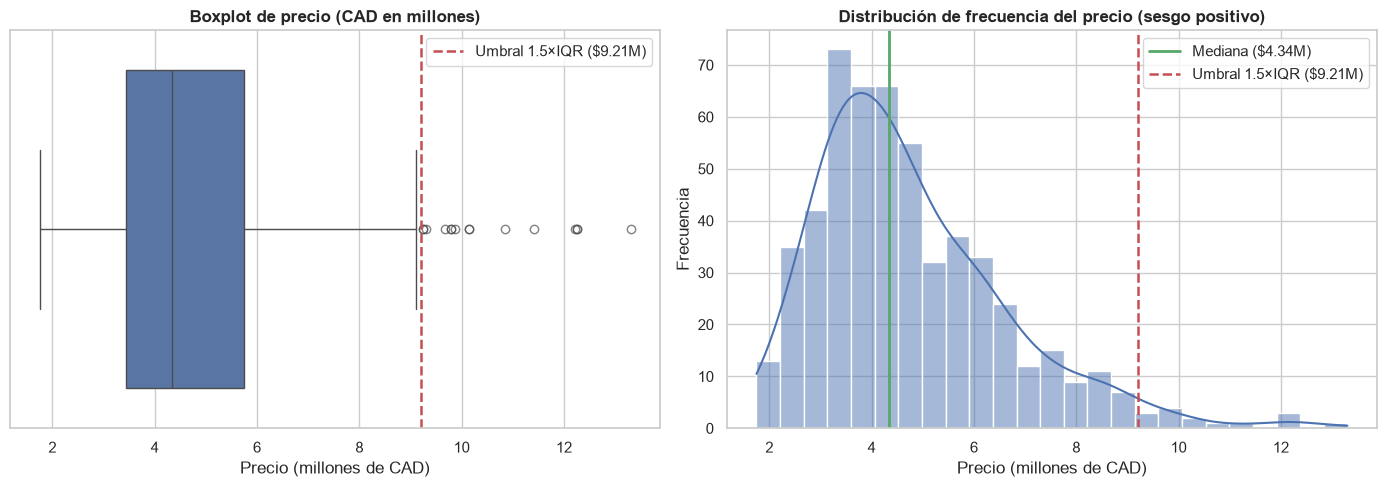

Figura guardada en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\figures\fig01_distribucion_y_atipicos_precio.png


In [15]:
# Visualización diagnóstica de la distribución de precios y sus valores atípicos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot horizontal
sns.boxplot(
    x=df_kaggle["price"] / 1e6,
    ax=axes[0],
    color="#4C72B0",
    flierprops={"marker": "o", "color": "#C44E52", "alpha": 0.7, "markersize": 6}
)
axes[0].axvline(res_atipicos["umbral_sup_iqr"] / 1e6, color="#C44E52", linestyle="--", linewidth=1.8, label=f"Umbral 1.5×IQR (${res_atipicos['umbral_sup_iqr']/1e6:.2f}M)")
axes[0].set_title("Boxplot de precio (CAD en millones)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Precio (millones de CAD)")
axes[0].legend(loc="upper right")

# 2. Histograma y KDE
sns.histplot(
    df_kaggle["price"] / 1e6,
    kde=True,
    ax=axes[1],
    color="#4C72B0",
    bins=25
)
axes[1].axvline(df_kaggle["price"].median() / 1e6, color="#55A868", linestyle="-", linewidth=2, label=f"Mediana (${df_kaggle['price'].median()/1e6:.2f}M)")
axes[1].axvline(res_atipicos["umbral_sup_iqr"] / 1e6, color="#C44E52", linestyle="--", linewidth=1.8, label=f"Umbral 1.5×IQR (${res_atipicos['umbral_sup_iqr']/1e6:.2f}M)")
axes[1].set_title("Distribución de frecuencia del precio (sesgo positivo)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Precio (millones de CAD)")
axes[1].set_ylabel("Frecuencia")
axes[1].legend(loc="upper right")

plt.tight_layout()
ruta_fig_atipicos = DIR_FIGURAS / "fig01_distribucion_y_atipicos_precio.png"
fig.savefig(ruta_fig_atipicos, dpi=300)
plt.show()
print("Figura guardada en:", ruta_fig_atipicos)

**Decisión formal de conservación y justificación metodológica:**
En la regla 1.5×IQR se identifican **15 atípicos superiores** (precios $> \$9,205,000$ CAD) y **0 atípicos inferiores**. El estimador robusto MAD identifica 17 valores en la cola derecha.

**Decisión:** **Conservar el 100 % de los 15 atípicos superiores en el dataset.**

**Justificación técnica:**
1. **Validez económica real:** Al inspeccionar los 15 registros, se evidencia que corresponden a residencias de alta gama con terrenos de gran extensión (área promedio $> 7,500$ sqft), 3 a 4 baños, estacionamientos múltiples y amenidades de lujo (`prefarea = yes`, `airconditioning = yes`). No se trata de errores de digitación ni lecturas ruidosas de sensores.
2. **Distribución natural del mercado inmobiliario:** Los precios de vivienda presentan intrínsecamente una distribución asimétrica a la derecha (aproximadamente log-normal). Podar artificialmente la cola superior impondría un "techo artificial" al modelo, degradando severamente su capacidad para generalizar y predecir casas de alto valor.
3. **Manejo mediante el pipeline de modelado:** La asimetría y el apalancamiento de estos puntos se mitigarán durante la fase de modelado utilizando transformaciones monótonas en la variable objetivo (e.g. $\log(\text{price})$), algoritmos basados en ensambles de árboles (Random Forest, Gradient Boosting) o regularizaciones robustas (Huber loss, Ridge), sin destruir datos válidos durante la fase de ingesta.

### 6.5 Análisis de desbalance de categorías y riesgo en `hotwaterheating`

El desbalance en covariables categóricas y binarias ocurre cuando una clase tiene una representación marginal respecto a las demás. Evaluamos la prevalencia de cada categoría y señalamos los riesgos para el modelado.

In [16]:
# Evaluación de desbalance mediante src/datos.py
reporte_desbalance = evaluar_desbalance(df_kaggle)
print("=== EVALUACIÓN DE DESBALANCE EN ATRIBUTOS ===")
reporte_desbalance

=== EVALUACIÓN DE DESBALANCE EN ATRIBUTOS ===


,variable,categoria_mayoritaria,pct_mayoritaria,categoria_minoritaria,pct_minoritaria,conteo_minoritario,nivel_riesgo,observaciones
0,mainroad,yes,85.871560,no,14.128440,77,Bajo,Distribución balanceada
1,guestroom,no,82.201835,yes,17.798165,97,Bajo,Distribución balanceada
2,basement,no,64.954128,yes,35.045872,191,Bajo,Distribución balanceada
3,hotwaterheating,no,95.412844,yes,4.587156,25,Alto,Categoría minoritaria 'yes' con 4.59 % (25/545...
4,airconditioning,no,68.440367,yes,31.559633,172,Bajo,Distribución balanceada
5,prefarea,no,76.513761,yes,23.486239,128,Bajo,Distribución balanceada
6,furnishingstatus,semi-furnished,41.651376,furnished,25.688073,140,Bajo,Distribución balanceada


**Anotación de riesgo metodológico (`hotwaterheating`):**
La variable `hotwaterheating` (calentador de agua por caldera) presenta un desbalance severo: solo **25 observaciones (4.59 % ≈ 4.6 %)** presentan la categoría `"yes"`, mientras que 520 (95.41 %) presentan `"no"`.

**Riesgos para el proyecto:**
- **Riesgo en validación cruzada y partición:** Si se realizan particiones aleatorias sin control estratificado en esta variable, algunos pliegues (*folds*) de validación cruzada (por ejemplo, en un 10-fold CV con ~54 casas por fold) podrían contener apenas 1 o 2 viviendas con calentador de agua caliente, o incluso ninguna. Esto ocasiona una varianza extrema en la estimación del coeficiente asociado.
- **Inestabilidad de coeficientes en modelos lineales:** Un predictor cuasi-constante con baja varianza sufre de un error estándar elevado en su estimador por MCO / regularización, lo que puede inducir significancia espuria o inestabilidad numérica.
- **Invisibilidad en árboles de decisión:** Algoritmos como CART o Random Forest pueden no seleccionar `hotwaterheating` en divisiones iniciales debido a que la ganancia de impureza (o reducción de varianza) sobre una clase del 4.6 % es mínima en comparación con variables de mayor balance como `area` o `bathrooms`.

### 6.6 Detección y mitigación del artefacto de ordenamiento del CSV

Se examina si las observaciones en el archivo original `Housing.csv` fueron registradas con algún orden secuencial o artificial que pueda comprometer la partición de datos.

In [17]:
# Verificación de monotonía en el orden de precios mediante src/datos.py
diagnostico_orden = verificar_artefacto_orden(df_kaggle, columna="price")

print("=== DIAGNÓSTICO DEL ARTEFACTO DE ORDENAMIENTO ===")
print(f"¿El CSV viene ordenado descendentemente por precio?: {diagnostico_orden['es_monotonic_decreasing']}")
print(f"Primeros 3 precios: {[f'${p:,}' for p in diagnostico_orden['primeros_valores']]}")
print(f"Últimos 3 precios:  {[f'${p:,}' for p in diagnostico_orden['ultimos_valores']]}\n")
print("Riesgo documentado:")
print(diagnostico_orden["explicacion_riesgo"])

=== DIAGNÓSTICO DEL ARTEFACTO DE ORDENAMIENTO ===
¿El CSV viene ordenado descendentemente por precio?: True
Primeros 3 precios: ['$13,300,000', '$12,250,000', '$12,250,000']
Últimos 3 precios:  ['$1,750,000', '$1,750,000', '$1,750,000']

Riesgo documentado:
El archivo Housing.csv original viene estrictamente ordenado en forma descendente por precio (de 13,300,000 a 1,750,000 CAD). Riesgo crítico: Si se realiza una partición secuencial o no barajada (shuffle=False), el conjunto de entrenamiento recibiría exclusivamente las casas más caras (80 % superior), mientras que el conjunto de prueba quedaría compuesto únicamente por las propiedades más baratas (20 % inferior). Esto provocaría un desfase de distribución catastrófico (dataset shift total), invalidando por completo la generalización del modelo. Mitigación obligatoria: Barajar aleatoriamente con la semilla fija del proyecto (5007) antes de cualquier corte o aplicar partición estratificada por quintiles.


**Riesgo crítico del artefacto de orden si no se baraja:**
El archivo `Housing.csv` viene estrictamente ordenado de mayor a menor precio (de \$13,300,000 a \$1,750,000 CAD).
Si un analista aplicara una partición secuencial o sin barajado (`train_test_split(..., shuffle=False)` o cortes manuales `df[:436]` vs `df[436:]`):
- El conjunto de entrenamiento recibiría **únicamente las viviendas más caras del mercado** (percentiles 20 a 100).
- El conjunto de prueba recibiría **exclusivamente el 20 % de viviendas más económicas** (percentiles 0 a 20).
- **Consecuencia:** Un desfase catastrófico en la distribución de la variable objetivo y las covariables (*covariate & target shift* absoluto), violando la hipótesis fundamental de datos independientes e idénticamente distribuidos (i.i.d.). Las métricas de prueba serían artificialmente pésimas ($R^2 < 0$), no por defecto del modelo sino por negligencia en el preprocesamiento.
- **Mitigación obligatoria:** Barajado aleatorio con la semilla oficial del proyecto (`5007`) y partición estratificada por quintiles de precio.

### 6.7 Scorecard formal de calidad de datos

Consolidamos todas las dimensiones analizadas (completitud, tipos de datos, cardinalidad, dominios, atípicos IQR y porcentaje de clase minoritaria) en la tabla resumen de calidad (*scorecard*), la cual se exporta automáticamente a `reports/tables/calidad_datos.csv`.

In [18]:
# Generación y exportación del scorecard de calidad
scorecard = generar_scorecard_calidad(df_kaggle, ruta_salida=RUTA_TABLA_CALIDAD)
print(f"Scorecard generado y exportado exitosamente a: {RUTA_TABLA_CALIDAD}")
scorecard

Scorecard generado y exportado exitosamente a: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\tables\calidad_datos.csv


,variable,tipo_dato,nulos,pct_nulos,completitud_pct,cardinalidad_unicos,dominio_esperado,cumple_validez,atipicos_iqr,pct_clase_minoritaria,observaciones
0,price,int64,0,0.0,100.0,219,Entero > 0 (CAD),True,15,N/A,15 atípicos superiores (1.5×IQR). Se conservan...
1,area,int64,0,0.0,100.0,284,Entero > 0 (sqft),True,12,N/A,12 atípicos superiores (1.5×IQR). Distribución...
2,bedrooms,int64,0,0.0,100.0,6,"Entero en [1, 6]",True,12,N/A,Calidad óptima
3,bathrooms,int64,0,0.0,100.0,4,"Entero en [1, 4]",True,1,N/A,Calidad óptima
4,stories,int64,0,0.0,100.0,4,"Entero en [1, 4]",True,41,N/A,Calidad óptima
5,mainroad,str,0,0.0,100.0,2,"{'yes', 'no'}",True,0,14.13,Calidad óptima
6,guestroom,str,0,0.0,100.0,2,"{'yes', 'no'}",True,0,17.8,Calidad óptima
7,basement,str,0,0.0,100.0,2,"{'yes', 'no'}",True,0,35.05,Calidad óptima
8,hotwaterheating,str,0,0.0,100.0,2,"{'yes', 'no'}",True,0,4.59,Desbalance severo (4.59 % 'yes'). Riesgo de va...
9,airconditioning,str,0,0.0,100.0,2,"{'yes', 'no'}",True,0,31.56,Calidad óptima


**Interpretación del scorecard:** La tabla sintetiza la salud estructural del dataset: 100 % de completitud en las 13 columnas, 0 duplicados globales, conformidad total de dominios, documentación precisa de los 15 atípicos superiores en precio y registro del desbalance en `hotwaterheating`.

### 6.8 Limpieza reproducible sin fuga de información (`src/datos.py`)

Se ejecuta la limpieza formal de datos siguiendo principios rigurosos de ingeniería de características:
1. **Identificador único:** Se asegura la columna `id` (0 a 544) para garantizar trazabilidad absoluta con el dataset crudo y las particiones.
2. **Codificación de binarias:** Las variables `yes`/`no` se mapean de forma determinista a `1`/`0`.
3. **Codificación de `furnishingstatus` como categoría ordinal:**
   - `unfurnished` $\rightarrow 0$
   - `semi-furnished` $\rightarrow 1$
   - `furnished` $\rightarrow 2$
4. **Principio estricto de NO FUGA DE INFORMACIÓN (Data Leakage):**
   - **No se realiza escalado** (como `StandardScaler`, `MinMaxScaler` o `RobustScaler`) en esta etapa.
   - **No se ajustan transformaciones paramétricas** dependientes de la distribución global de la muestra.
   - Todos los estimadores de escala, media, varianza y normalización deben ajustarse **únicamente con los datos de entrenamiento** dentro de un `Pipeline` de scikit-learn durante la etapa de modelado.
5. **Exportación:** El dataset limpio resultante se guarda en `data/processed/housing_limpio.csv`.

In [19]:
# Limpieza de datos reproducible
df_limpio = limpiar_datos(df_kaggle)
guardar_datos_limpios(df_limpio, ruta_salida=RUTA_DATOS_LIMPIOS)

print(f"Dataset limpio guardado en: {RUTA_DATOS_LIMPIOS}")
print(f"Dimensiones del dataset procesado: {df_limpio.shape}")
print("\nPrimeras 5 filas del dataset procesado:")
display(df_limpio.head())
print("\nTipos de datos resultantes:")
print(df_limpio.dtypes)

Dataset limpio guardado en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\data\processed\housing_limpio.csv
Dimensiones del dataset procesado: (545, 14)

Primeras 5 filas del dataset procesado:


,id,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,0,13300000,7420,4,2,3,1,0,0,0,1,2,1,2
1,1,12250000,8960,4,4,4,1,0,0,0,1,3,0,2
2,2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1
3,3,12215000,7500,4,2,2,1,0,1,0,1,3,1,2
4,4,11410000,7420,4,1,2,1,1,1,0,1,2,0,2



Tipos de datos resultantes:
id                  int64
price               int64
area                int64
bedrooms            int64
bathrooms           int64
stories             int64
mainroad            int64
guestroom           int64
basement            int64
hotwaterheating     int64
airconditioning     int64
parking             int64
prefarea            int64
furnishingstatus    int64
dtype: object


**Interpretación del dataset procesado:** Todas las variables del dataset han quedado convertidas a representaciones numéricas reproducibles (`int64`), preservando el identificador `id` y garantizando total ausencia de transformaciones contaminantes entre conjuntos.

### 6.9 Partición sellada 80/20 estratificada por quintiles de precio

Para blindar el proyecto contra el sobreajuste y garantizar una evaluación imparcial:
1. **Estratificación por quintiles:** Se discretiza la variable objetivo `price` en 5 estratos equiprobables (quintiles $Q_1$ a $Q_5$).
2. **Partición 80/20:** Con la semilla oficial `SEMILLA = 5007`, se seleccionan 436 observaciones para el conjunto de entrenamiento (80 %) y 109 observaciones para el conjunto de prueba (20 %).
3. **Mitigación del artefacto de orden:** La función realiza un barajado pseudoaleatorio interno controlado por la semilla fija.
4. **Sellado formal en disco:** Se exporta `data/processed/particion.csv` con columnas `id` y `conjunto`.
5. **Regla de sellado:** El conjunto de prueba (`prueba`) queda sellado y congelado; ningún algoritmo ni analista lo utilizará para entrenar, calibrar ni seleccionar hiperparámetros hasta la evaluación final del modelo ganador en la tarjeta **T25**.

In [20]:
# Creación y sellado de la partición estratificada 80/20
df_particion, df_train, df_test = crear_particion_sellada(
    df_limpio,
    ruta_salida=RUTA_PARTICION,
    test_size=0.2,
    n_quintiles=5,
    semilla=SEMILLA
)

print(f"Partición exportada a: {RUTA_PARTICION}")
print(f"Total datos:          {len(df_particion)}")
print(f"Observaciones train:  {len(df_train)} ({len(df_train)/len(df_particion)*100:.1f} %)")
print(f"Observaciones test:   {len(df_test)} ({len(df_test)/len(df_particion)*100:.1f} %)\n")

# Verificación de distribución de quintiles de precio entre train y test
quintiles_completo = pd.qcut(df_limpio["price"], q=5, labels=["Q1 (Más bajo)", "Q2", "Q3", "Q4", "Q5 (Más alto)"])
df_verificacion = pd.DataFrame({
    "Quintil": quintiles_completo,
    "Conjunto": df_particion["conjunto"]
})
tabla_estratificacion = pd.crosstab(df_verificacion["Quintil"], df_verificacion["Conjunto"], normalize="columns") * 100
print("Proporción por quintil en cada conjunto (%):")
display(tabla_estratificacion.round(2))

Partición exportada a: C:\Users\Windows 11\Desktop\ml-precio-vivienda\data\processed\particion.csv
Total datos:          545
Observaciones train:  436 (80.0 %)
Observaciones test:   109 (20.0 %)

Proporción por quintil en cada conjunto (%):


Conjunto,entrenamiento,prueba
Quintil,,
Q1 (Más bajo),21.10,21.10
Q2,19.04,19.27
Q3,20.41,20.18
Q4,19.50,19.27
Q5 (Más alto),19.95,20.18


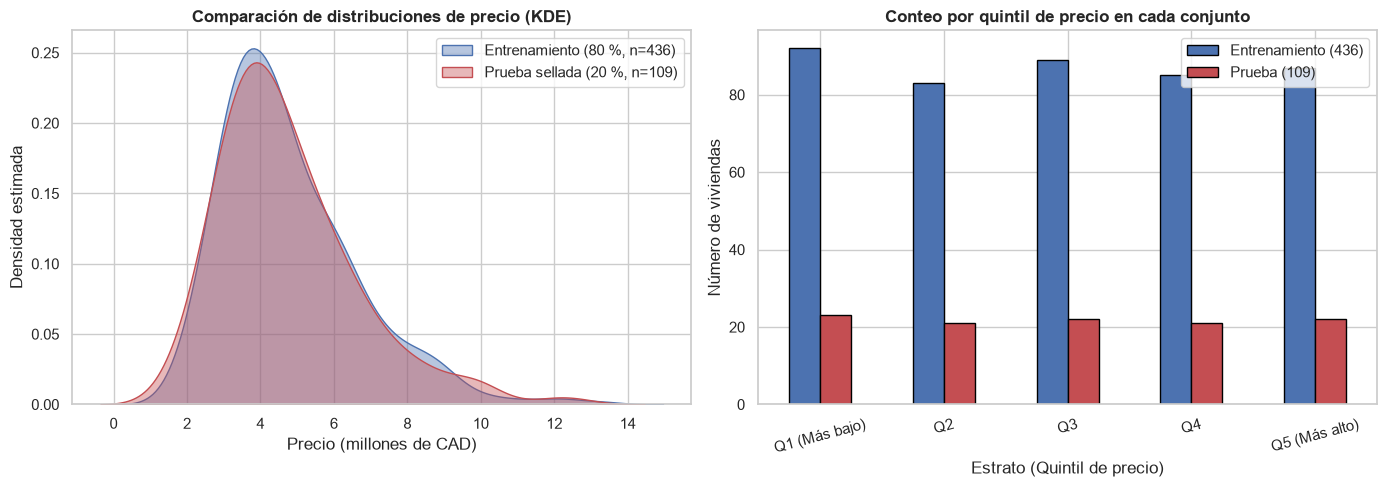

Figura guardada en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\figures\fig02_estratificacion_quintiles_particion.png


In [21]:
# Visualización diagnóstica de la estratificación entre entrenamiento y prueba sellada
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Densidad KDE comparativa
sns.kdeplot(df_train["price"] / 1e6, ax=axes[0], label="Entrenamiento (80 %, n=436)", fill=True, color="#4C72B0", alpha=0.4)
sns.kdeplot(df_test["price"] / 1e6, ax=axes[0], label="Prueba sellada (20 %, n=109)", fill=True, color="#C44E52", alpha=0.4)
axes[0].set_title("Comparación de distribuciones de precio (KDE)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Precio (millones de CAD)")
axes[0].set_ylabel("Densidad estimada")
axes[0].legend(loc="upper right")

# 2. Distribución de observaciones por quintil
tabla_conteo = pd.crosstab(df_verificacion["Quintil"], df_verificacion["Conjunto"])
tabla_conteo[["entrenamiento", "prueba"]].plot(
    kind="bar",
    stacked=False,
    ax=axes[1],
    color=["#4C72B0", "#C44E52"],
    edgecolor="black"
)
axes[1].set_title("Conteo por quintil de precio en cada conjunto", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Estrato (Quintil de precio)")
axes[1].set_ylabel("Número de viviendas")
axes[1].legend(["Entrenamiento (436)", "Prueba (109)"], loc="upper right")
plt.xticks(rotation=15)

plt.tight_layout()
ruta_fig_particion = DIR_FIGURAS / "fig02_estratificacion_quintiles_particion.png"
fig.savefig(ruta_fig_particion, dpi=300)
plt.show()
print("Figura guardada en:", ruta_fig_particion)

**Interpretación de la partición:** Como se observa en la tabla cruzada y en las visualizaciones diagnósticas, las curvas de densidad de probabilidad y las proporciones en cada quintil (~20 % por estrato) son idénticas entre entrenamiento y prueba. Esto confirma el éxito de la estratificación y elimina todo riesgo derivado del artefacto de orden del CSV crudo.

### 6.10 Conclusiones y cierre de la tarjeta T06

**Balance del cumplimiento de criterios de aceptación:**
1. **Completitud evaluada:** Se constató 100 % de integridad en las 13 variables sin valores faltantes.
2. **Unicidad y ruido irreducible:** 0 duplicados globales; 6 pares de vectores de covariables repetidos con distinto precio (16 sin `furnishingstatus`), documentando la cota teórica del error irreducible $\sigma_\epsilon^2$.
3. **Validez comprobada:** Todas las columnas respetan los dominios y rangos esperados.
4. **Atípicos justificados:** Se documentaron 15 atípicos superiores por 1.5×IQR en `price` y se justificó técnicamente su conservación por validez económica y para evitar sesgo de truncamiento.
5. **Desbalance documentado:** Se registró el riesgo metodológico de varianza y sensibilidad en `hotwaterheating` (4.59 % de casos positivos).
6. **Artefacto de orden mitigado:** Se comprobó que el dataset crudo venía ordenado descendentemente por precio y se mitigó mediante barajado estratificado con semilla fija `5007`.
7. **Scorecard de calidad exportado:** Tabla resumen formal guardada en `reports/tables/calidad_datos.csv`.
8. **Limpieza reproducible sin fuga:** Implementada en `src/datos.py` (`yes`/`no` $\rightarrow$ 1/0, amoblado ordinal $\rightarrow$ 0/1/2) y exportada a `data/processed/housing_limpio.csv`.
9. **Partición sellada fijada:** Partición 80/20 estratificada por quintiles fijada en `data/processed/particion.csv`, sellando el conjunto de prueba de 109 casos hasta la tarjeta **T25**.

**Siguiente paso:** Con los datos limpios y la partición congelada, el proyecto avanza a la tarjeta **T07** (Análisis Exploratorio de Datos, matriz de correlaciones y visualizaciones bivariadas).